# Look at diet information within Arivale
First we will merge antibiotic use data with diet information. Then we will drop all the sparse columns, keeping only those that are sufficiently filled out to be useful to us. We will look at the diet distribution for each question. Finally, we will add microbiome information, such as shannon diversity and predicted SCFA production. 

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from statsmodels.graphics.factorplots import interaction_plot
from docx import Document
import re

# apply settings so the lib knows where the data is
import arivale_data_interface as adi
adi.apply_isb_config()
from tableone import TableOne

import sys
import os
sys.path.append(os.path.abspath(os.path.join('..')))
from regression_functions import *

## Data processing/merging

In [2]:
# Data import
abx_covar = pd.read_csv("../data/rh_abx_covar_alpha_divs_rarefied.csv", dtype={"public_client_id":str})
diet = pd.read_csv("../data/diet_collapsed.csv", dtype={'public_client_id':str})

In [3]:
abx_covar.days_in_program = abx_covar.days_in_program.astype(float)

In [4]:
abx_covar

,public_client_id,PC1,PC2,PC3,PC4,PC5,days_in_program,meds_blood_sugar,meds_cholesterol,abx_recency,...,statin,dosage,medications_free_text,statin_binary,vendor,GLYCOHEMOGLOBINA1C,LDL_CHOLCALCULATION,observed_features,shannon_index,berger_parker
0,01001661,-0.502318,-0.209167,-0.158374,-0.037808,0.019072,8.0,No,No,none,...,NaN,NaN,NaN,0,LCA,5.6,84.0,77.243743,2.617081,0.376926
1,01001798,-0.063097,-0.016664,-0.021592,0.067403,-0.657988,0.0,No,Yes,three,...,atorvastatin,40 mg,omeprazole 20mg 1 daily--nabumetone 750mg 2x d...,1,LCA,5.6,103.0,85.920289,2.734163,0.261329
2,01002183,0.064613,-0.017430,-0.028642,0.078008,0.027224,6.0,No,No,three,...,NaN,NaN,NaN,0,Quest,5.3,118.0,89.702850,3.432714,0.099684
3,01002412,0.065735,-0.018133,-0.037775,0.115139,0.044114,10.0,No,No,none,...,NaN,NaN,NaN,0,Quest,4.8,97.0,121.494626,3.388333,0.130139
4,01002885,0.062390,-0.015236,-0.048144,0.031535,-0.002983,0.0,Yes,No,three,...,NaN,NaN,NaN,0,LCA,5.4,73.0,96.927731,3.515964,0.101056
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1962,HX768417,0.062040,-0.012187,-0.026662,0.035231,0.023383,5.0,No,Yes,three,...,rosuvastatin,40 mg,Aspirin 81 MG/daily; Omeprazole 20 MG/daily\nR...,1,LCA,6.1,73.0,105.033207,2.499101,0.397320
1963,HX872254,0.068381,-0.013649,-0.042652,0.072764,0.033464,70.0,No,Yes,three,...,atorvastatin,20 mg,"Warfarin - 5mg twice a week, 7.5mg five times ...",1,LCA,5.5,100.0,87.468631,1.934490,0.568705
1964,HX883708,0.064444,-0.026034,-0.038521,0.062859,0.053261,452.0,No,No,three,...,NaN,NaN,NaN,0,LCA,5.2,183.0,101.583029,2.690564,0.387809
1965,HX977604,0.059870,-0.023874,-0.049069,0.099279,0.065594,117.0,No,No,three,...,NaN,NaN,NaN,0,LCA,4.8,56.0,104.898696,3.552141,0.149252


In [5]:
# Prepare for merge
diet.rename(columns={'vendor':'diet_vendor'}, inplace=True)
diet = diet.sort_values(by="days_in_program").dropna(subset='days_in_program')
abx_covar = abx_covar.sort_values(by="days_in_program")

# Merge with measure
abx_diet = pd.merge_asof(
    abx_covar, diet, 
    by="public_client_id", 
    on="days_in_program", 
    direction="nearest", 
    tolerance=30.0)
abx_diet

,public_client_id,PC1,PC2,PC3,PC4,PC5,days_in_program,meds_blood_sugar,meds_cholesterol,abx_recency,...,assessment:diet:freq_white_fish:int,assessment:diet:freq_yogurt:int,assessment:diet:milk:int,assessment:diet:salt_in_food:int,assessment:diet:slices_of_bread:int,assessment:diet:spread:int,assessment:diet:sugar:int,assessment:diet:sugar_coffee:int,assessment:lifestyle:grains:enum,response_percentage
0,01568974,-0.149388,0.030381,0.617446,0.176120,0.042827,-7.0,No,No,twelve,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(2) 3-4,0.232143
1,01092042,-0.503311,-0.208429,-0.160230,-0.046219,0.061394,-7.0,No,No,none,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(1) 1-2,0.232143
2,01684342,0.063423,-0.019438,-0.035673,-0.008457,0.001391,-5.0,No,No,none,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(1) 1-2,0.232143
3,01601230,0.062362,-0.028922,-0.034839,0.086872,0.029430,-5.0,No,No,none,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(0) Zero/less than 1 per day,0.232143
4,01789632,0.065513,-0.020356,-0.039293,0.063760,0.027713,-1.0,No,No,none,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(1) 1-2,0.232143
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1962,HX883708,0.064444,-0.026034,-0.038521,0.062859,0.053261,452.0,No,No,three,...,(3) Once per week,(1) Less than once per month,(4) Other kind,(1) Generally add salt to food without tasting...,(1) Less than 1,(7) Do not spread fat on bread,(2) No,(2) No,(0) Zero/less than 1 per day,1.000000
1963,01201199,0.065988,-0.013680,-0.050926,0.044681,0.035107,712.0,No,No,three,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1964,01440344,-0.490879,-0.196570,-0.115884,-0.019040,0.133794,731.0,No,Yes,three,...,(4) 2-4 times per week,(2) 1-3 times per month,(4) Other kind,(3) Taste food but only occasionally add salt,(3) 2-3,(4) Other,(2) No,(3) Yes,(2) 3-4,1.000000
1965,01382823,0.065718,-0.021335,-0.035135,0.089997,0.031969,752.0,No,No,three,...,(2) 1-3 times per month,(6) Once per day,(4) Other kind,(2) Taste food and then generally add salt,(2) 1,(4) Other,(2) No,(3) Yes,(1) 1-2,0.982143


In [6]:
# Uncomment to see number of nans
# original_nans = abx_diet.isna().sum()[:-20]
# original_nans

In [7]:
# Drop sparse col
threshold = 100
nan_counts = abx_diet.isna().sum()
columns_to_drop = nan_counts[nan_counts > threshold].index.tolist()
# Drop the columns
abx_diet = abx_diet.drop(columns=columns_to_drop)
abx_diet = abx_diet.drop(columns='response_percentage')

In [8]:
abx_diet.iloc[:,29:]

,assessment:lifestyle:achohol_type:enum,assessment:lifestyle:alcohol_days_a_week:enum,assessment:lifestyle:breakfast:enum,assessment:lifestyle:cruciferous_vegetables:enum,assessment:lifestyle:snack:enum,assessment:lifestyle:fruits:enum,assessment:lifestyle:vegetables:enum,assessment:lifestyle:sugary_drinks:enum,assessment:lifestyle:water:enum,assessment:lifestyle:alcohol_drinks_a_day:enum,assessment:lifestyle:diet:enum,assessment:lifestyle:grains:enum
0,(2) Wine,(1) 1-2 days,(0) Daily,(1) 3-4 times per week,(0) Daily,(0) Zero/less than 1 per day,(2) 2-3,(0) Zero/less than 1 per day,(1) Less than 3 cups per day,(1) 1-2 drinks,(0) No special diet,(2) 3-4
1,(3) Liquor,(1) 1-2 days,(0) Daily,(0) Daily,(0) Daily,(2) 2-3,(2) 2-3,(0) Zero/less than 1 per day,(4) More than 8 cups per day,(1) 1-2 drinks,(0) No special diet,(1) 1-2
2,(3) Liquor,(4) I drink alcohol daily,(0) Daily,(2) Once per week,(4) Less than once per month,(2) 2-3,(1) 1,(0) Zero/less than 1 per day,(2) 4-5 cups per day,(1) 1-2 drinks,(0) No special diet,(1) 1-2
3,(2) Wine,(3) 5-6 days,(0) Daily,(0) Daily,(1) 3-4 times per week,(1) 1,(2) 2-3,(0) Zero/less than 1 per day,(3) 6-8 cups per day,(1) 1-2 drinks,"(6) Low carbohydrate (Atkins, South Beach, Zon...",(0) Zero/less than 1 per day
4,(0) No preference,(0) I do not drink,(0) Daily,(0) Daily,(4) Less than once per month,(2) 2-3,(2) 2-3,(0) Zero/less than 1 per day,(2) 4-5 cups per day,(0) I do not drink,(1) Vegetarian,(1) 1-2
...,...,...,...,...,...,...,...,...,...,...,...,...
1962,(3) Liquor,(1) 1-2 days,(1) 3-4 times per week,(1) 3-4 times per week,(0) Daily,(1) 1,(2) 2-3,(0) Zero/less than 1 per day,(0) I don’t usually drink water,(1) 1-2 drinks,(3) Gluten-free,(0) Zero/less than 1 per day
1963,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1964,(2) Wine,(0) I do not drink,(0) Daily,(1) 3-4 times per week,(0) Daily,(0) Zero/less than 1 per day,(2) 2-3,(0) Zero/less than 1 per day,(2) 4-5 cups per day,(1) 1-2 drinks,(8) Other,(2) 3-4
1965,(2) Wine,NaN,(0) Daily,(1) 3-4 times per week,(0) Daily,(2) 2-3,(2) 2-3,(0) Zero/less than 1 per day,(3) 6-8 cups per day,(1) 1-2 drinks,(0) No special diet,(1) 1-2


Shorten column names so they aren't so verbose.

In [9]:
col_to_rename = abx_diet.iloc[:,29:].columns.tolist()
new_col_names = {col: col.split(':')[2] for col in col_to_rename}
abx_diet.rename(columns=new_col_names, inplace=True)
abx_diet.rename(columns={'achohol_type': 'alcohol_type', 
                         'cruciferous_vegetables':'cruciferous_vegetables_frequency',
                         'fruits':'fruits_per_day',
                         'vegetables':'vegetables_per_day',
                         'sugary_drinks':'sugary_drinks_per_day',
                         'water':'cups_water_per_day', 
                         'grains':'grains_per_day'}, inplace=True)
abx_diet.columns

Index(['public_client_id', 'PC1', 'PC2', 'PC3', 'PC4', 'PC5',
       'days_in_program', 'meds_blood_sugar', 'meds_cholesterol',
       'abx_recency', 'sex', 'age', 'BMI_CALC', 'hx_t2dm', 'hx_gestational',
       'gluc_dysreg', 'eGFR', 'centered_eGFR', 'centered_BMI',
       'abx_recency_three', 'abx_recency_twelve', 'vendor_dashboard',
       'statin_binary', 'vendor', 'GLYCOHEMOGLOBINA1C', 'observed_features',
       'shannon_index', 'berger_parker', 'diet_vendor', 'alcohol_type',
       'alcohol_days_a_week', 'breakfast', 'cruciferous_vegetables_frequency',
       'snack', 'fruits_per_day', 'vegetables_per_day',
       'sugary_drinks_per_day', 'cups_water_per_day', 'alcohol_drinks_a_day',
       'diet', 'grains_per_day'],
      dtype='object')

Import data on stool vendors; need to add as a covar. 

In [10]:
# stool_vendors = pd.read_csv('../data/stool_vendors.csv', dtype={'public_client_id':str})

In [11]:
# abx_diet = abx_diet.merge(stool_vendors[['public_client_id','vendor_dashboard']].copy(),
#                           how='left', on='public_client_id')

In [12]:
abx_diet.abx_recency.value_counts()

abx_recency
none      1219
twelve     429
three      319
Name: count, dtype: int64

## Diet distributions

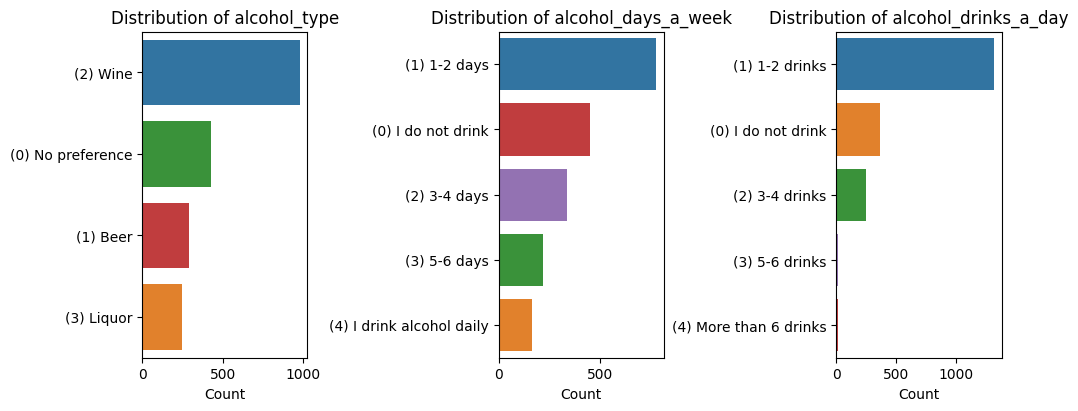

In [13]:
# Alcohol histograms
alc_qs = ['alcohol_type','alcohol_days_a_week', 'alcohol_drinks_a_day']

fig, axes = plt.subplots(1, len(alc_qs), 
                         figsize=(10, 4), 
                         constrained_layout=True)

# Loop through categories and plot on each subplot
for ax, category in zip(axes, alc_qs):
    sns.countplot(y=abx_diet[category], 
                  order=abx_diet[category].value_counts().index, 
                  hue=abx_diet[category], legend=False, 
                  ax=ax)
    ax.set_xlabel('Count')
    ax.set_ylabel('')
    ax.set_title(f'Distribution of {category}')

plt.show()

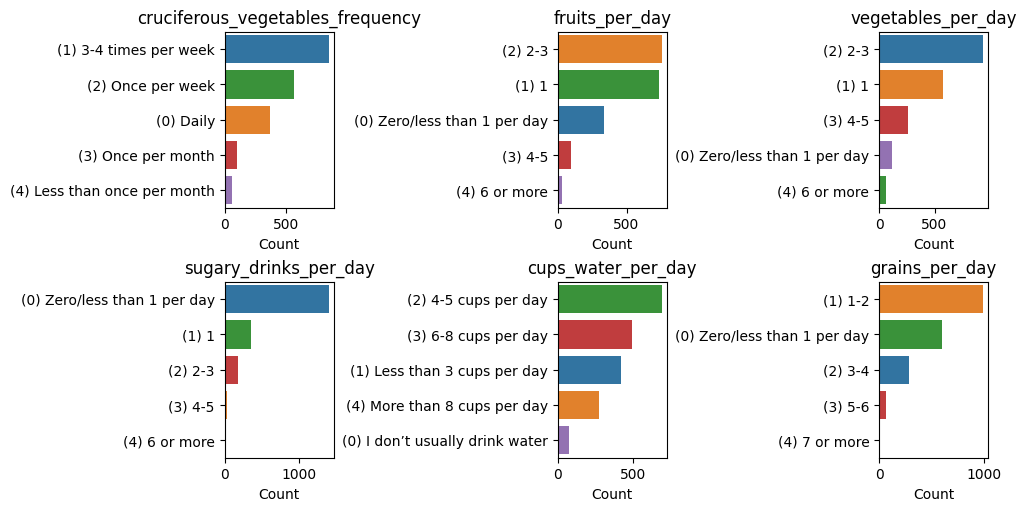

In [14]:
# Healthy eating
healthy_qs = ['cruciferous_vegetables_frequency', 'fruits_per_day','vegetables_per_day', 
              'sugary_drinks_per_day', 'cups_water_per_day', 'grains_per_day']

fig, axes = plt.subplots(2, 3, figsize=(10, 5), constrained_layout=True)
axes = axes.flatten()

# Loop through categories and plot on each subplot
for ax, category in zip(axes, healthy_qs):
    sns.countplot(y=abx_diet[category], 
                  order=abx_diet[category].value_counts().index, 
                  hue=abx_diet[category], legend=False, 
                  ax=ax)
    ax.set_xlabel('Count')
    ax.set_ylabel('')
    ax.set_title(f'{category}')
plt.show()

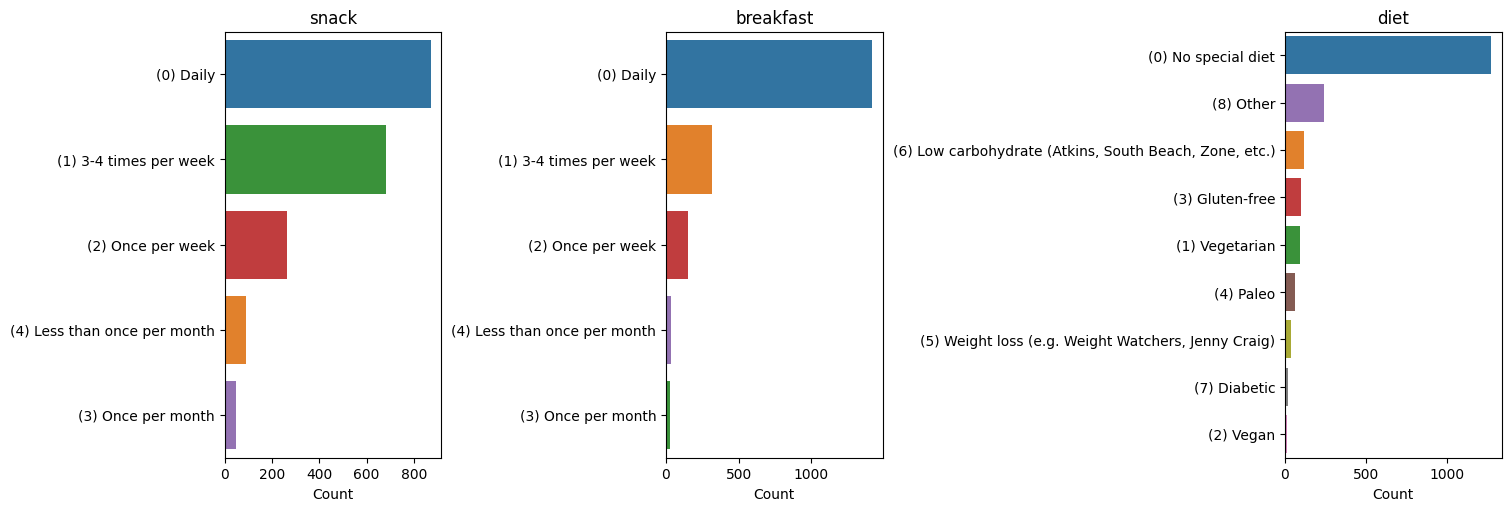

In [15]:
# Other
other_qs = ['snack', 'breakfast', 'diet']

fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
axes = axes.flatten()

# Loop through categories and plot on each subplot
for ax, category in zip(axes, other_qs):
    sns.countplot(y=abx_diet[category], 
                  order=abx_diet[category].value_counts().index, 
                  hue=abx_diet[category], legend=False, 
                  ax=ax)
    ax.set_xlabel('Count')
    ax.set_ylabel('')
    ax.set_title(f'{category}')
# plt.show()

# Plot Shannon on Y-axis

## Alcohol

In [16]:
alc_qs = ['alcohol_type','alcohol_days_a_week', 'alcohol_drinks_a_day']

# Change some longer text for plot below
shortened = {
    'alcohol_days_a_week': {'(0) I do not drink': '(0) None', 
                            '(4) I drink alcohol daily': '(4) Daily'},
    'alcohol_drinks_a_day': {'(0) I do not drink': '(0) None', 
                            '(4) More than 6 drinks': '(4) 6+ drinks'}}
    
abx_diet.replace(shortened, inplace=True)

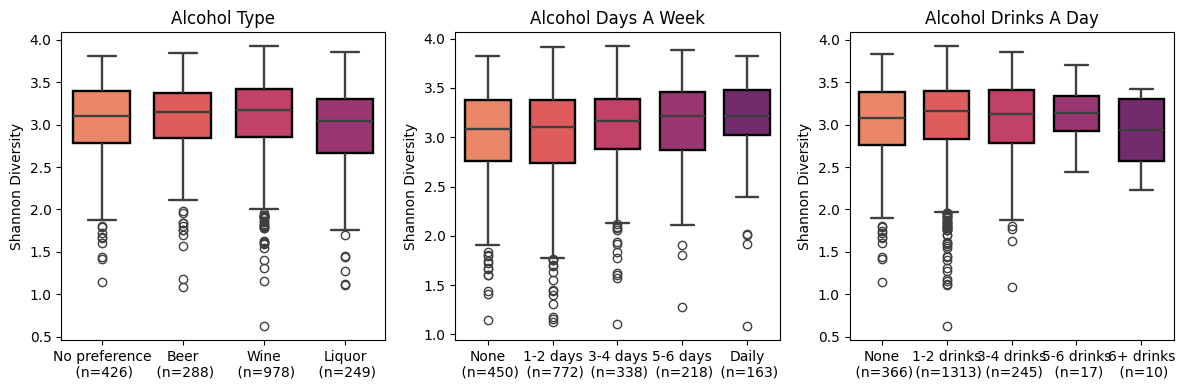

In [17]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(12, 4))  
axes = axes.flatten()  # Flatten for easy iteration

# Function to extract number from categorical labels
def extract_number(label):
    match = re.search(r"\((\d+)\)", str(label))            # Looks for a number inside parentheses
    return int(match.group(1)) if match else float("inf")  # Use `inf` for missing numbers

# Loop through each column and create a subplot
for i, col in enumerate(alc_qs):
    sns.set_style("whitegrid")
    ax = axes[i]

    # Unique answers
    unique_categories = abx_diet[col].dropna().unique()

    # Sort x-axis based answer order
    sorted_order = sorted(unique_categories, key=extract_number)

    # Compute group size 
    group_counts = abx_diet[col].value_counts().reindex(sorted_order, fill_value=0)
    labels_with_n = [f"{cat.split(') ')[1]}\n (n={group_counts[cat]})" for cat in sorted_order]

    sns.boxplot(data=abx_diet, y='shannon_index', x=col,
                showfliers=True, linewidth=1.7, 
                order=sorted_order, palette=None,
                ax=ax, legend=False, 
                width=0.7,
                boxprops={'edgecolor': 'black'})
    
    # Manually color each box
    local_palette = sns.color_palette("flare", 5)
    for patch, color in zip(ax.patches, local_palette):
        patch.set_facecolor(color)

    ax.set_xticks(range(len(sorted_order)))         # Tick positions match label count
    ax.set_xticklabels(labels_with_n, fontsize=10)  # Now set the labels
    ax.set_title(col.replace('_', ' ').title())
    ax.set_ylabel('Shannon Diversity')
    ax.set_xlabel('')

plt.tight_layout()
# plt.show()

## Healthy (or unhealthy) eating behavior

In [18]:
healthy_qs = ['cruciferous_vegetables_frequency', 'fruits_per_day','vegetables_per_day', 
              'sugary_drinks_per_day', 'cups_water_per_day', 'grains_per_day']

In [19]:
# Change some longer text for plot below
shortened = {
    'cruciferous_vegetables_frequency': {'(1) 3-4 times per week': '(1) 3-4x/week', 
                            '(4) Less than once per month': '(4) > 1/month',
                            '(2) Once per week':'(2) 1/week', 
                            '(3) Once per month':'(3) 1/month'},
    'fruits_per_day': {'(0) Zero/less than 1 per day': '(0) 0'},
    'vegetables_per_day': {'(0) Zero/less than 1 per day': '(0) 0'}, 
    'sugary_drinks_per_day': {'(0) Zero/less than 1 per day': '(0) 0'}, 
    'cups_water_per_day': {'(0) I don’t usually drink water': '(0) None', 
                           '(1) Less than 3 cups per day':'(1) > 3 cups', 
                           '(4) More than 8 cups per day':'(4) 8+ cups',
                           '(2) 4-5 cups per day':'(2) 4-5 cups',
                           '(3) 6-8 cups per day':'(2) 6-8 cups'},
    'grains_per_day': {'(0) Zero/less than 1 per day': '(0) 0', '(4) 7 or more':'(4) 7+'}                     
  }
    
abx_diet.replace(shortened, inplace=True)

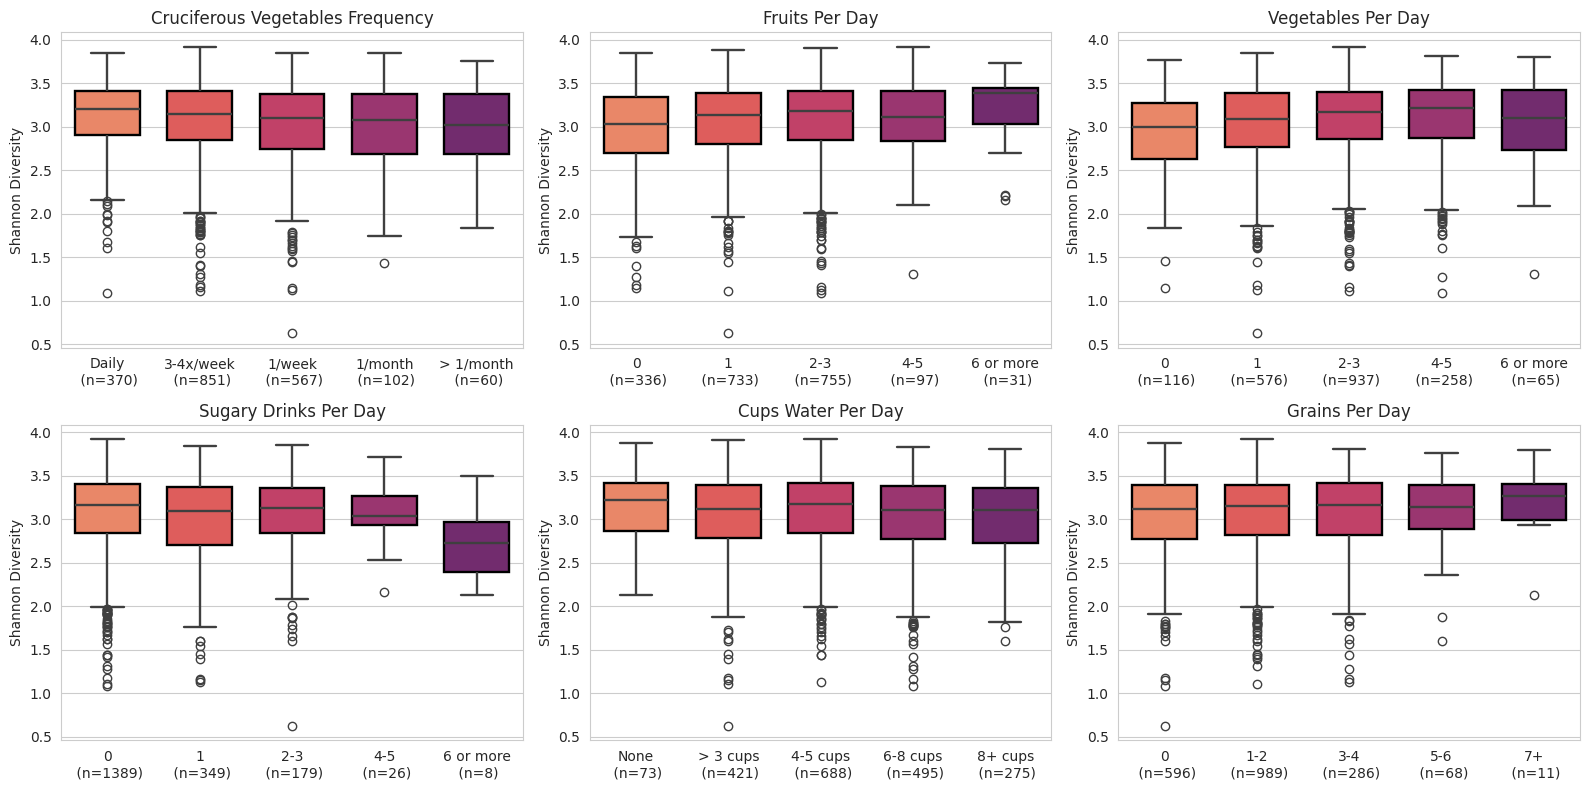

In [20]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 8))  
axes = axes.flatten()  # Flatten for easy iteration

# Function to extract number from categorical labels
def extract_number(label):
    match = re.search(r"\((\d+)\)", str(label))            # Looks for a number inside parentheses
    return int(match.group(1)) if match else float("inf")  # Use `inf` for missing numbers

# Loop through each column and create a subplot
for i, col in enumerate(healthy_qs):
    sns.set_style("darkgrid")
    ax = axes[i]
    # Unique answers
    unique_categories = abx_diet[col].dropna().unique()

    # Sort X-axis based answer order
    sorted_order = sorted(unique_categories, key=extract_number)

    # Compute group size 
    group_counts = abx_diet[col].value_counts().reindex(sorted_order, fill_value=0)
    labels_with_n = [f"{cat.split(') ')[1]}\n (n={group_counts[cat]})" for cat in sorted_order]

    sns.boxplot(data=abx_diet, y='shannon_index', x=col,
                showfliers=True, linewidth=1.7, 
                order=sorted_order, palette=None,
                ax=ax, legend=False, 
                width=0.7,
                boxprops={'edgecolor': 'black'})
    
    # Manually color each box
    local_palette = sns.color_palette("flare", 5)
    for patch, color in zip(ax.patches, local_palette):
        patch.set_facecolor(color)

    ax.set_xticks(range(len(sorted_order)))         # Tick positions match label count
    ax.set_xticklabels(labels_with_n, fontsize=10)  # Now set the labels
    ax.set_title(col.replace('_', ' ').title())
    ax.set_ylabel('Shannon Diversity')
    ax.set_xlabel('')

plt.tight_layout()
# plt.show()

## Other diet questions

In [21]:
other_qs = ['snack', 'breakfast', 'diet']

In [22]:
# Change some longer text for plot below
shortened = {
    'diet': {'(6) Low carbohydrate (Atkins, South Beach, Zone, etc.)': 
             '(6) Low carb', 
             '(5) Weight loss (e.g. Weight Watchers, Jenny Craig)': 
             '(5) Weight loss'},
    'breakfast': {'(1) 3-4 times per week': '(1) 3-4x/week', 
                  '(4) Less than once per month': '(4) > 1/month',
                  '(2) Once per week':'(2) 1/week', 
                  '(3) Once per month':'(3) 1/month'},
    'snack': {'(1) 3-4 times per week': '(1) 3-4x/week', 
                  '(4) Less than once per month': '(4) > 1/month',
                  '(2) Once per week':'(2) 1/week', 
                  '(3) Once per month':'(3) 1/month'}
  }

abx_diet.replace(shortened, inplace=True)

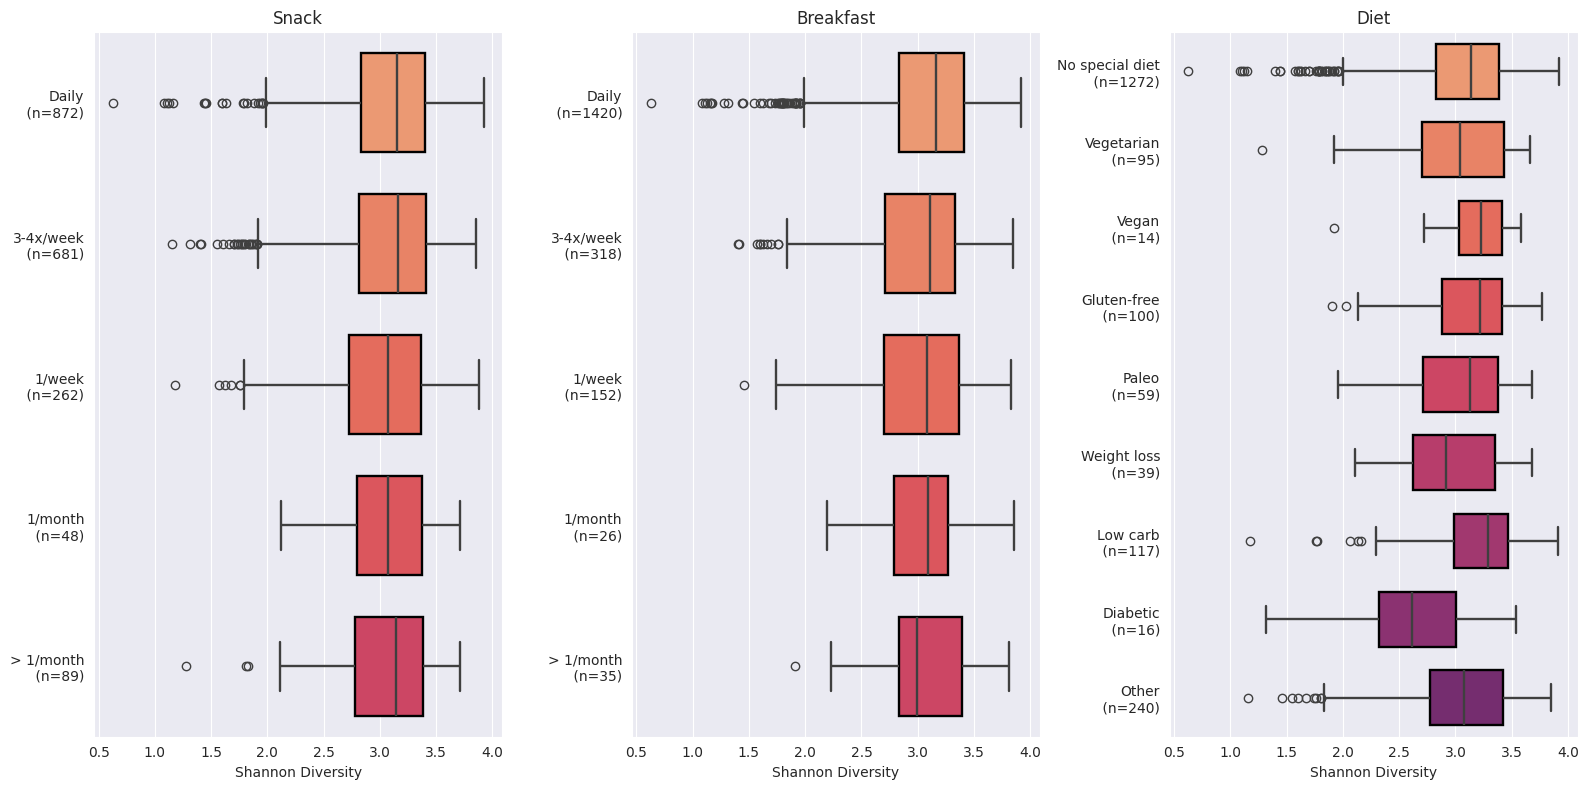

In [23]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 8))  
axes = axes.flatten()  # Flatten for easy iteration

# Function to extract number from categorical labels
def extract_number(label):
    match = re.search(r"\((\d+)\)", str(label))  # Looks for a number inside parentheses
    return int(match.group(1)) if match else float("inf")  # Use `inf` for missing numbers

# Loop through each column and create a subplot
for i, col in enumerate(other_qs):
    sns.set_style("darkgrid")
    ax = axes[i]

    # Unique answers
    unique_categories = abx_diet[col].dropna().unique()

    # Sort categories based answer order
    sorted_order = sorted(unique_categories, key=extract_number)

    # Compute group size 
    group_counts = abx_diet[col].value_counts().reindex(sorted_order, fill_value=0)
    labels_with_n = [f"{cat.split(') ')[1]}\n (n={group_counts[cat]})" for cat in sorted_order]

    sns.boxplot(data=abx_diet, y=col, x='shannon_index',
                showfliers=True, linewidth=1.7, 
                order=sorted_order, palette=None,
                ax=ax, legend=False, 
                width=0.7,  # Adjust width to prevent very thin boxes
                boxprops={'edgecolor': 'black'})
    
    # Manually color each box
    local_palette = sns.color_palette("flare", 10)
    for patch, color in zip(ax.patches, local_palette):
        patch.set_facecolor(color)

    ax.set_yticks(range(len(sorted_order)))         # Tick positions match label count
    ax.set_yticklabels(labels_with_n, fontsize=10)  # Now set the labels
    ax.set_title(col.replace('_', ' ').title())
    ax.set_xlabel('Shannon Diversity')
    ax.set_ylabel('')

plt.tight_layout()
# plt.show()

# Binarize daily dietary behaviors

## Create a mapping scheme

I am going to remove some variables because they can't be they are somewhat redundant or group sizes would be too small (especially when further split into the abx groups). For example, most people have no special diet. Other group sizes are really small.

In [24]:
# 'alcohol_days_a_week', 'diet', cups_water_per_day

In [25]:
def map_survey_responses(value, mapping_dict):
    """Map a survey response to a category based on a dictionary, keeping NaNs intact."""
    if pd.isna(value):  # Ensure NaNs remain as NaNs
        return np.nan  
    
    value = str(value)  # Convert to string for dictionary lookup
    
    for key, category in mapping_dict.items():
        if value in key:
            return category
    return value  # Return original value if not in the dictionary

In [26]:
column_mappings_binary = {
    'fruits_per_day': {('(0) 0'): 0,
                       ('(1) 1', '(2) 2-3', '(3) 4-5', '(4) 6 or more'): 1},
    'vegetables_per_day': {('(0) 0'): 0,
                           ('(1) 1', '(2) 2-3', '(3) 4-5', '(4) 6 or more'): 1},
    'sugary_drinks_per_day': {('(0) 0'): 0,
                              ('(1) 1', '(2) 2-3', '(3) 4-5', '(4) 6 or more'): 1},
    'alcohol_drinks_a_day': {('(0) None'): 0, 
                             ('(1) 1-2 drinks', '(2) 3-4 drinks','(3) 5-6 drinks','(4) 6+ drinks'): 1},
    'grains_per_day': {('(0) 0'): 0,
                       ('(1) 1-2', '(2) 3-4','(3) 5-6','(4) 7+'): 1}, 
    'cruciferous_vegetables_frequency': {('(4) > 1/month', '(3) 1/month', '(2) 1/week'): 0, 
                                ('(1) 3-4x/week','(0) Daily'): 1}, 
    'breakfast': {('(4) > 1/month', '(3) 1/month', '(2) 1/week'): 0, 
                  ('(1) 3-4x/week','(0) Daily'): 1},
    'snack': {('(4) > 1/month', '(3) 1/month', '(2) 1/week'): 0,
              ('(1) 3-4x/week','(0) Daily'): 1}
    }

# Apply the mapping to each column
for col, mapping_dict in column_mappings_binary.items():
    abx_diet[col + '_binary'] = abx_diet[col].apply(map_survey_responses, args=(mapping_dict,))
abx_diet.columns

Index(['public_client_id', 'PC1', 'PC2', 'PC3', 'PC4', 'PC5',
       'days_in_program', 'meds_blood_sugar', 'meds_cholesterol',
       'abx_recency', 'sex', 'age', 'BMI_CALC', 'hx_t2dm', 'hx_gestational',
       'gluc_dysreg', 'eGFR', 'centered_eGFR', 'centered_BMI',
       'abx_recency_three', 'abx_recency_twelve', 'vendor_dashboard',
       'statin_binary', 'vendor', 'GLYCOHEMOGLOBINA1C', 'observed_features',
       'shannon_index', 'berger_parker', 'diet_vendor', 'alcohol_type',
       'alcohol_days_a_week', 'breakfast', 'cruciferous_vegetables_frequency',
       'snack', 'fruits_per_day', 'vegetables_per_day',
       'sugary_drinks_per_day', 'cups_water_per_day', 'alcohol_drinks_a_day',
       'diet', 'grains_per_day', 'fruits_per_day_binary',
       'vegetables_per_day_binary', 'sugary_drinks_per_day_binary',
       'alcohol_drinks_a_day_binary', 'grains_per_day_binary',
       'cruciferous_vegetables_frequency_binary', 'breakfast_binary',
       'snack_binary'],
      dtype='obje

In [27]:
diet_cols = ['fruits_per_day_binary','vegetables_per_day_binary', 
             'sugary_drinks_per_day_binary','alcohol_drinks_a_day_binary', 
             'grains_per_day_binary','cruciferous_vegetables_frequency_binary',
             'alcohol_type','snack_binary', 'breakfast_binary']

In [28]:
melted = abx_diet.melt(
    id_vars=['abx_recency'],
    value_vars=diet_cols,
    var_name='diet_question',
    value_name='behavior')

counts = (melted
    .groupby(['behavior', 'diet_question', 'abx_recency'])
    .size()
    .reset_index(name='count'))

diet_bin_enumeration = counts.pivot_table(
    index=['diet_question', 'behavior'],
    columns='abx_recency',
    values='count',
    fill_value=0)
diet_bin_enumeration

abx_recency                                                  none  three  \
diet_question                           behavior                           
alcohol_drinks_a_day_binary             0.0                 225.0   61.0   
                                        1.0                 984.0  253.0   
alcohol_type                            (0) No preference   274.0   60.0   
                                        (1) Beer            188.0   37.0   
                                        (2) Wine            613.0  157.0   
                                        (3) Liquor          134.0   50.0   
breakfast_binary                        0.0                 129.0   27.0   
                                        1.0                1080.0  287.0   
cruciferous_vegetables_frequency_binary 0.0                 434.0  121.0   
                                        1.0                 774.0  193.0   
fruits_per_day_binary                   0.0                 208.0   52.0   
                                        1.0                1000.0  264.0   
grains_per_day_binary                   0.0                 375.0   99.0   
                                        1.0                 833.0  215.0   
snack_binary                            0.0                 248.0   59.0   
                                        1.0                 961.0  256.0   
sugary_drinks_per_day_binary            0.0                 889.0  219.0   
                                        1.0                 320.0   95.0   
vegetables_per_day_binary               0.0                  64.0   17.0   
                                        1.0                1145.0  298.0   

abx_recency                                                twelve  
diet_question                           behavior                   
alcohol_drinks_a_day_binary             0.0                  80.0  
                                        1.0                 348.0  
alcohol_type                            (0) No preference    92.0  
                                        (1) Beer             63.0  
                                        (2) Wine            208.0  
                                        (3) Liquor           65.0  
breakfast_binary                        0.0                  57.0  
                                        1.0                 371.0  
cruciferous_vegetables_frequency_binary 0.0                 174.0  
                                        1.0                 254.0  
fruits_per_day_binary                   0.0                  76.0  
                                        1.0                 352.0  
grains_per_day_binary                   0.0                 122.0  
                                        1.0                 306.0  
snack_binary                            0.0                  92.0  
                                        1.0                 336.0  
sugary_drinks_per_day_binary            0.0                 281.0  
                                        1.0                 147.0  
vegetables_per_day_binary               0.0                  35.0  
                                        1.0                 393.0

In [29]:
# diet_bin_enumeration.columns

In [30]:
abx_diet = abx_diet.dropna(subset=diet_cols)
abx_diet.abx_recency.value_counts() # Minimum of all obs cols = 1865

abx_recency
none      1208
twelve     428
three      301
Name: count, dtype: int64

In [31]:
columns = diet_cols
categorical = diet_cols
groupby = 'abx_recency'

table1 = TableOne(abx_diet, columns=columns, 
                  categorical=categorical, missing=False,
                  groupby=groupby,pval=True, htest_name=True)

In [32]:
latex_str = table1.to_latex()
with open("../data/diet_distributions_chi_square.tex", "w") as f:
    f.write(latex_str)

In [33]:
doc = Document()
n_index_levels = diet_bin_enumeration.index.nlevels

# Create table with extra columns for index
table = doc.add_table(
    rows=diet_bin_enumeration.shape[0] + 2,
    cols=n_index_levels + diet_bin_enumeration.shape[1]
)
table.style = 'Table Grid'

table.cell(0, n_index_levels).text = str(diet_bin_enumeration.columns.name)
for j in range(1, diet_bin_enumeration.shape[1]):
    table.cell(0, n_index_levels).merge(table.cell(0, n_index_levels + j))


for i, name in enumerate(diet_bin_enumeration.index.names):
    table.cell(1, i).text = str(name)
for j, col in enumerate(diet_bin_enumeration.columns):
    table.cell(1, n_index_levels + j).text = str(col)

# ---- Data rows ----
for row_idx, (index_vals, row) in enumerate(diet_bin_enumeration.iterrows()):
    if n_index_levels == 1:
        index_vals = (index_vals,)
    
    for i, val in enumerate(index_vals):
        table.cell(row_idx + 2, i).text = str(val)
    
    for j, val in enumerate(row):
        table.cell(row_idx + 2, n_index_levels + j).text = str(val)

# Save
doc.save('../data/diet_table.docx')

## Run linear regressions to investigate interaction term

In [34]:
shannon_binary = run_diet_regressions(diet_cols, abx_diet, "shannon_index")
shannon_binary.sort_values(by='q_value').head()

,food_bin,term,beta,t_stat,p_value,n,q_value
0,fruits_per_day_binary,C(abx_recency)[T.three]:C(fruits_per_day_binar...,0.165433,2.326114,0.020116,1937.0,0.211549
3,vegetables_per_day_binary,C(abx_recency)[T.twelve]:C(vegetables_per_day_...,-0.186658,-2.071308,0.038463,1937.0,0.211549
7,alcohol_drinks_a_day_binary,C(abx_recency)[T.twelve]:C(alcohol_drinks_a_da...,-0.126473,-2.123861,0.033809,1937.0,0.211549
11,cruciferous_vegetables_frequency_binary,C(abx_recency)[T.twelve]:C(cruciferous_vegetab...,-0.105095,-2.210735,0.027172,1937.0,0.211549
4,sugary_drinks_per_day_binary,C(abx_recency)[T.three]:C(sugary_drinks_per_da...,-0.107207,-1.839483,0.065999,1937.0,0.263229


In [35]:
features_binary = run_diet_regressions(diet_cols, abx_diet, "observed_features")
features_binary[features_binary['q_value'] < 0.2].sort_values(by='q_value')

,food_bin,term,beta,t_stat,p_value,n,q_value
16,alcohol_type,C(abx_recency)[T.three]:C(alcohol_type)[T.(3) ...,-13.665043,-3.218085,0.001312,1937.0,0.028866
7,alcohol_drinks_a_day_binary,C(abx_recency)[T.twelve]:C(alcohol_drinks_a_da...,-8.101138,-2.909972,0.003656,1937.0,0.040219
4,sugary_drinks_per_day_binary,C(abx_recency)[T.three]:C(sugary_drinks_per_da...,-6.211533,-2.278844,0.022786,1937.0,0.167096
0,fruits_per_day_binary,C(abx_recency)[T.three]:C(fruits_per_day_binar...,7.065602,2.121653,0.033995,1937.0,0.186971


In [36]:
bp_binary = run_diet_regressions(diet_cols, abx_diet, "berger_parker")
bp_binary.sort_values(by='q_value').head()

,food_bin,term,beta,t_stat,p_value,n,q_value
3,vegetables_per_day_binary,C(abx_recency)[T.twelve]:C(vegetables_per_day_...,0.051636,2.140070,0.032475,1937.0,0.374845
11,cruciferous_vegetables_frequency_binary,C(abx_recency)[T.twelve]:C(cruciferous_vegetab...,0.027020,2.120679,0.034077,1937.0,0.374845
7,alcohol_drinks_a_day_binary,C(abx_recency)[T.twelve]:C(alcohol_drinks_a_da...,0.028215,1.768561,0.077126,1937.0,0.565592
2,vegetables_per_day_binary,C(abx_recency)[T.three]:C(vegetables_per_day_b...,0.037509,1.151678,0.249597,1937.0,0.575290
5,sugary_drinks_per_day_binary,C(abx_recency)[T.twelve]:C(sugary_drinks_per_d...,0.014658,1.092108,0.274923,1937.0,0.575290


In [37]:
features_binary[features_binary['q_value'] < 0.2].sort_values(by='q_value').term.tolist()

['C(abx_recency)[T.three]:C(alcohol_type)[T.(3) Liquor]',
 'C(abx_recency)[T.twelve]:C(alcohol_drinks_a_day_binary)[T.1.0]',
 'C(abx_recency)[T.three]:C(sugary_drinks_per_day_binary)[T.1.0]',
 'C(abx_recency)[T.three]:C(fruits_per_day_binary)[T.1.0]']

In [38]:
# Set up aes preferences
sns.set_style(style="whitegrid",  rc={"xtick.bottom": True, 'ytick.left': True})

bin_order = ['(0) No preference', '(1) Beer', '(2) Wine', '(3) Liquor']  
abx_order = ['none', 'twelve', 'three']
markers_order=['o', 's', 'D']
legend_labels = {'none': 'None','three': '0 - 3 months','twelve': '3 - 12 months'}

# Make 3 month a little darker for the lineplot specifically
lp_pal = {'none': "#007ea7", 'twelve': "#80ced7", 'three': '#B9CACC'} 

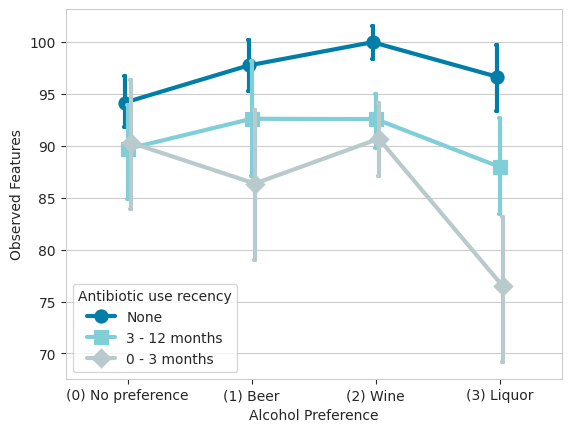

In [39]:
ax = sns.pointplot(data=abx_diet, x="alcohol_type", y="observed_features",
              hue="abx_recency", order=bin_order, hue_order=abx_order, palette=lp_pal, 
              markers=markers_order, capsize=0.01, ms=8, dodge=0.05, linewidth=3,
              errorbar=('ci', 95), n_boot=1000, legend=True)

plt.xlabel('Alcohol Preference')
plt.ylabel('Observed Features')

# Get current handles and labels
handles, labels = ax.get_legend_handles_labels()
new_labels = [legend_labels.get(label, label) for label in labels] # Replace labels 
plt.legend(handles, new_labels, title="Antibiotic use recency",
          loc='lower left')

plt.savefig("../figures/diet_interaction_obs_feats_alc_pref.pdf", dpi=300, bbox_inches="tight")

In [40]:
# Set preferences
sns.set_style(style="whitegrid")
sig_cols = ['alcohol_drinks_a_day_binary',
            'sugary_drinks_per_day_binary',
            'fruits_per_day_binary']
x_labels = ['0','1+']
lineorder = [["-","--","-"],
             ["-","-",":"],
             ["-","-",":"]
            ]

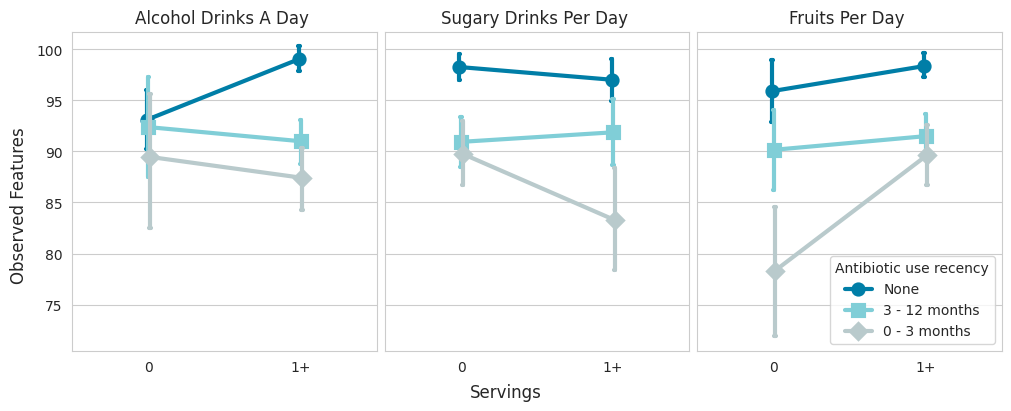

In [41]:
# Create subplots
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(10, 4),
                         sharey='row', constrained_layout=True)  
axes = axes.flatten()

# Loop through each column and create a subplot
for i, col in enumerate(sig_cols):
    ax = axes[i]
    sns.pointplot(data=abx_diet, x=col, y='observed_features', hue='abx_recency',
                  hue_order=abx_order, palette=lp_pal, linewidth=3, # linestyles=lineorder[i]
                  markers=markers_order, errorbar=('ci', 95), n_boot=1000,
                  ax=ax, capsize=0.01, ms=8, dodge=0.02
                 )

    # Set x-axis labels with counts
    # To make it more clear is 1+ servings 
    current_positions = ax.get_xticks()
    ax.set_xticks(current_positions, labels=x_labels)
    # Remove the binary term from title
    col = col.replace('binary', '')
    ax.set_title(col.replace('_', ' ').title())
    ax.set_xlabel('')
    ax.set_ylabel('')

for ax in axes:
    ax.legend_.remove()
    
# Add legend outside the subplots
handles, labels = axes[0].get_legend_handles_labels()
new_labels = [legend_labels.get(label, label) for label in labels] # Replace labels 
plt.legend(handles, new_labels, title="Antibiotic use recency",
          loc='lower right')

# Add shared labels
fig.supxlabel('Servings')
fig.supylabel('Observed Features')
plt.savefig("../figures/abx_diet_interaction_obsfeats_lineplots.pdf", dpi=300, bbox_inches="tight")
plt.show()

## Diet and CAZyme families

In [42]:
cazy_meta = pd.read_csv('../data/CAZY_meta.csv', dtype = {'public_client_id': str})

In [43]:
cazy_families = cazy_meta[['public_client_id', 'n_families']]

In [44]:
abx_diet_cazy = abx_diet.merge(cazy_families, how='left', on='public_client_id')

In [45]:
cazy_tests = run_diet_regressions(diet_cols, abx_diet_cazy, "n_families")
cazy_tests.sort_values(by='q_value').head()

,food_bin,term,beta,t_stat,p_value,n,q_value
11,cruciferous_vegetables_frequency_binary,C(abx_recency)[T.twelve]:C(cruciferous_vegetab...,-1.648741,-3.422946,0.000632,1937.0,0.013915
7,alcohol_drinks_a_day_binary,C(abx_recency)[T.twelve]:C(alcohol_drinks_a_da...,-1.645962,-2.725728,0.006474,1937.0,0.071217
15,alcohol_type,C(abx_recency)[T.twelve]:C(alcohol_type)[T.(2)...,-1.230366,-2.028793,0.042618,1937.0,0.265966
0,fruits_per_day_binary,C(abx_recency)[T.three]:C(fruits_per_day_binar...,1.378752,1.909021,0.056408,1937.0,0.265966
16,alcohol_type,C(abx_recency)[T.three]:C(alcohol_type)[T.(3) ...,-1.732410,-1.878632,0.060447,1937.0,0.265966


In [46]:
cazy_tests.sort_values(by='q_value').term.tolist()[0:3]

['C(abx_recency)[T.twelve]:C(cruciferous_vegetables_frequency_binary)[T.1.0]',
 'C(abx_recency)[T.twelve]:C(alcohol_drinks_a_day_binary)[T.1.0]',
 'C(abx_recency)[T.twelve]:C(alcohol_type)[T.(2) Wine]']

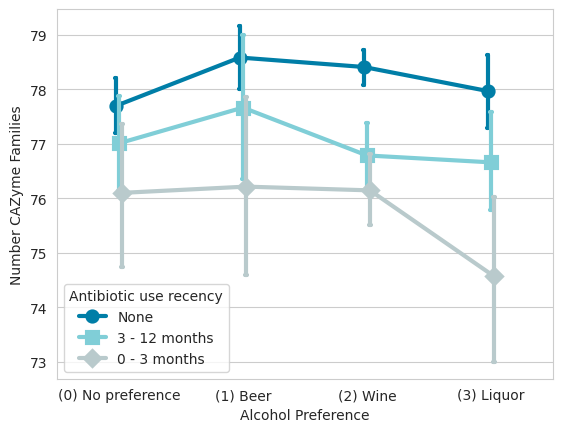

In [47]:
sns.set_style("whitegrid")
#line_order = ["-","-","--"]
ax = sns.pointplot(data=abx_diet_cazy, x="alcohol_type", y="n_families",
              hue="abx_recency", order=bin_order, hue_order=abx_order, palette=lp_pal, 
              markers=markers_order, capsize=0.01, ms=8, dodge=0.05, linewidth=3, # linestyles=line_order,
              errorbar=('ci', 95), n_boot=1000, legend=True)

plt.xlabel('Alcohol Preference')
plt.ylabel('Number CAZyme Families')

# Get current handles and labels
handles, labels = ax.get_legend_handles_labels()
new_labels = [legend_labels.get(label, label) for label in labels] # Replace labels 
plt.legend(handles, new_labels, title="Antibiotic use recency",
          loc='lower left')
plt.savefig("../figures/diet_interaction_CAZymes_alc_pref.pdf", dpi=300, bbox_inches="tight")

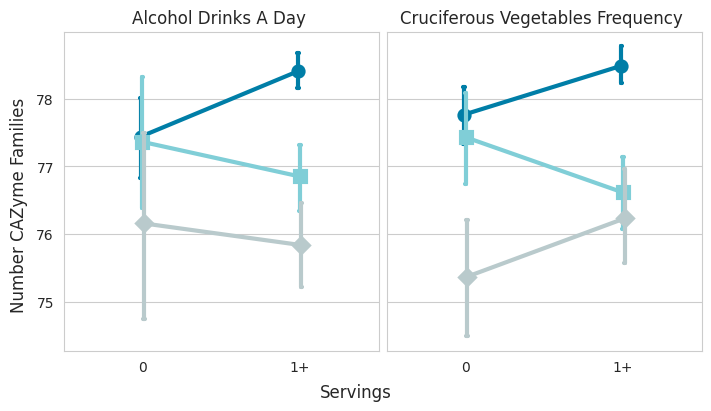

In [48]:
sns.set_style(style="whitegrid")
sig_cols = ['alcohol_drinks_a_day_binary',
            'cruciferous_vegetables_frequency_binary']
# line_order = [["-","--","-"],
#               ["-","--","-"]]

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(7, 4),
                         sharey='row', constrained_layout=True)  
axes = axes.flatten()

# Loop through each column and create a subplot
for i, col in enumerate(sig_cols):
    ax = axes[i]
    sns.pointplot(data=abx_diet_cazy, x=col, y='n_families', hue='abx_recency',
                  hue_order=abx_order, palette=lp_pal, linewidth=3, #linestyles=line_order[i], 
                  markers=markers_order, errorbar=('ci', 95), n_boot=1000,
                  ax=ax, capsize=0.01, ms=8, dodge=0.02)

    # Set x-axis labels with counts
    # To make it more clear is 1+ servings 
    current_positions = ax.get_xticks()
    ax.set_xticks(current_positions, labels=x_labels)
    # Remove the binary term from title
    col = col.replace('binary', '')
    ax.set_title(col.replace('_', ' ').title())
    ax.set_xlabel('')
    ax.set_ylabel('')

for ax in axes:
    ax.legend_.remove()

# Add shared labels
fig.supxlabel('Servings')
fig.supylabel('Number CAZyme Families')
plt.savefig("../figures/abx_diet_interaction_CAZymes_lineplots.pdf", dpi=300, bbox_inches="tight")
plt.show()

## Diet and SCFAs

In [49]:
arivale_predictions = pd.read_csv('../data/updated_arivale_scfas.csv')

In [50]:
abx_diet_scfas = abx_diet.merge(arivale_predictions, how='left', on='public_client_id')
abx_diet_scfas.head()

,public_client_id,PC1,PC2,PC3,PC4,PC5,days_in_program,meds_blood_sugar,meds_cholesterol,abx_recency,...,fruits_per_day_binary,vegetables_per_day_binary,sugary_drinks_per_day_binary,alcohol_drinks_a_day_binary,grains_per_day_binary,cruciferous_vegetables_frequency_binary,breakfast_binary,snack_binary,butyrate,propionate
0,01568974,-0.149388,0.030381,0.617446,0.176120,0.042827,-7.0,No,No,twelve,...,0.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,21.701064,7.564884
1,01092042,-0.503311,-0.208429,-0.160230,-0.046219,0.061394,-7.0,No,No,none,...,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,8.338067,1.525871
2,01684342,0.063423,-0.019438,-0.035673,-0.008457,0.001391,-5.0,No,No,none,...,1.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,25.364328,6.346801
3,01601230,0.062362,-0.028922,-0.034839,0.086872,0.029430,-5.0,No,No,none,...,1.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,21.389213,8.855014
4,01789632,0.065513,-0.020356,-0.039293,0.063760,0.027713,-1.0,No,No,none,...,1.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,22.513417,3.543784


In [51]:
butyrate_diet = run_diet_regressions(diet_cols, abx_diet_scfas, "butyrate")
butyrate_diet.sort_values(by='q_value').head()

,food_bin,term,beta,t_stat,p_value,n,q_value
11,cruciferous_vegetables_frequency_binary,C(abx_recency)[T.twelve]:C(cruciferous_vegetab...,-1.903450,-2.331282,0.019842,1937.0,0.436515
2,vegetables_per_day_binary,C(abx_recency)[T.three]:C(vegetables_per_day_b...,-3.731884,-1.786274,0.074213,1937.0,0.544227
17,alcohol_type,C(abx_recency)[T.twelve]:C(alcohol_type)[T.(3)...,2.541525,1.858099,0.063308,1937.0,0.544227
3,vegetables_per_day_binary,C(abx_recency)[T.twelve]:C(vegetables_per_day_...,-2.522393,-1.629702,0.103329,1937.0,0.568308
15,alcohol_type,C(abx_recency)[T.twelve]:C(alcohol_type)[T.(2)...,1.161928,1.135279,0.256401,1937.0,0.817353


In [52]:
propionate_diet = run_diet_regressions(diet_cols, abx_diet_scfas, "propionate")
propionate_diet.sort_values(by='q_value').head()

,food_bin,term,beta,t_stat,p_value,n,q_value
3,vegetables_per_day_binary,C(abx_recency)[T.twelve]:C(vegetables_per_day_...,-1.309037,-2.171666,0.030003,1937.0,0.660067
1,fruits_per_day_binary,C(abx_recency)[T.twelve]:C(fruits_per_day_bina...,-0.500478,-1.222562,0.221645,1937.0,0.690627
6,alcohol_drinks_a_day_binary,C(abx_recency)[T.three]:C(alcohol_drinks_a_day...,-0.541701,-1.147938,0.251137,1937.0,0.690627
4,sugary_drinks_per_day_binary,C(abx_recency)[T.three]:C(sugary_drinks_per_da...,-0.489551,-1.255541,0.209435,1937.0,0.690627
7,alcohol_drinks_a_day_binary,C(abx_recency)[T.twelve]:C(alcohol_drinks_a_da...,-0.510394,-1.280994,0.200351,1937.0,0.690627


In [53]:
# abx_diet_cazy.to_csv('../data/abx_diet_cazy.csv', index=False)